# Warp Bubble Notebook

**What this is.** This notebook takes the warp-drive ideas from the author's handwritten notes, puts the equations into code, and shows what they do in pictures. Every chart has a plain-English caption, and every caption is also printed inside the saved image in `figures/`, so the pictures make sense on their own.

How to read it:
- **f** is the bubble's *shape*. f = 1 means "inside the bubble", where the ship rides along. f = 0 means ordinary, untouched space. The **wall** is the in-between zone where space gets squeezed in front of the ship and stretched behind it.
- All results are reported in ordinary units: metres, seconds, kilograms.
- The author's equations are coded **exactly as written**. Where something looks off, we show "as written" next to "the alternative" instead of quietly changing it.

The full plan is in `docs/warp-bubble-notebook-spec.md`. The math lives in `warp/shapes.py`, with tests in `tests/`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from warp import shapes
from warp.plotting import COLORS, LINESTYLES, phone_figure, save_figure, use_phone_style

use_phone_style()

## 1. The bubble wall: Alcubierre's tanh vs. the cosine wall

All of the exotic negative energy a warp bubble needs sits in its **wall**, and how much it needs depends on how **steep** that wall is: the energy density goes as the steepness squared. Alcubierre's 1994 design uses a tanh-shaped wall whose sharpness is left as a free setting (σ); here we set it to make the wall 1 m thick, the example size Pfenning & Ford used. The author's idea, the **Vorwaller Metric**, is a smooth cosine-shaped wall that can be made much thicker, which makes it far less steep. Here we draw both, with a bubble radius of R = 100 m.

**Yardstick for "thickness".** A tanh wall has soft tails, so its thickness needs a definition. We use the standard one from Pfenning & Ford (1997, eq. 5): the width of a straight ramp that has the same steepness as the wall's middle. That gives Δ ≈ 2/σ, so a 1 m tanh wall has σ = 2 per metre. The author also used σ = 2.0 in the dual-shell design, which matches this yardstick exactly.

The author's cosine wall has a clean edge: it starts at R and ends at exactly R + Δ, so the author's Δ measures the *whole* wall from start to finish. On Pfenning & Ford's steepness yardstick, the same wall counts as 2Δ/π ≈ 0.64 Δ thick. We label the cosine walls with their own Δ and convert wherever the comparison matters.

In [2]:
R = 100.0                              # bubble radius, m
DELTAS = [1.0, 10.0, 100.0, 1000.0]    # The author's cosine wall thicknesses, m
SIGMA = shapes.sigma_for_wall_thickness(1.0, R)   # σ giving a 1 m tanh wall (Pfenning & Ford eq. 5)
print(f"σ for a 1 m Alcubierre wall: {SIGMA:.6f} per metre")

# Radius grid: 5 cm steps everywhere, plus 1 mm steps around the thin walls at 100 m.
r = np.unique(np.concatenate([np.linspace(0.0, 1150.0, 23_001), np.linspace(95.0, 110.0, 15_001)]))

walls = [("Alcubierre tanh, 1 m wall", COLORS["black"], LINESTYLES[0],
          shapes.alcubierre_f(r, R, SIGMA), shapes.alcubierre_df(r, R, SIGMA))]
for (d, color, ls) in zip(DELTAS, ["orange", "sky", "green", "vermillion"], LINESTYLES[1:]):
    walls.append((f"cosine wall, Δ = {d:g} m", COLORS[color], ls,
                  shapes.cosine_wall_f(r, R, d), shapes.cosine_wall_df(r, R, d)))

σ for a 1 m Alcubierre wall: 2.000000 per metre


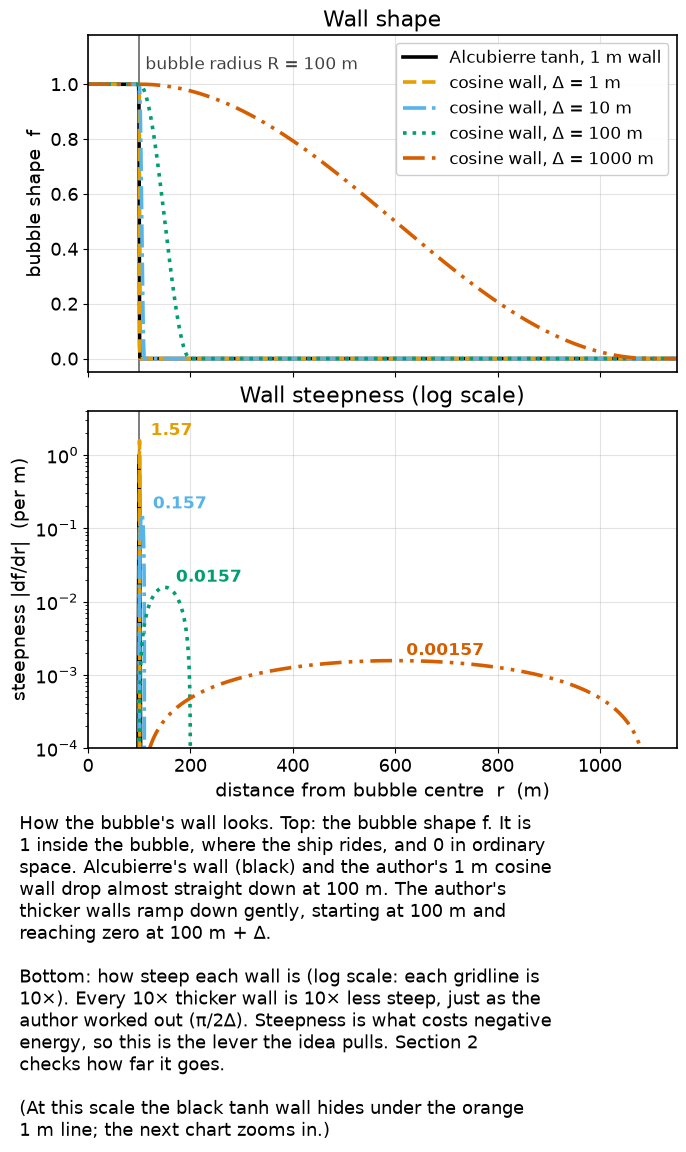

saved 01_wall_shapes.png


In [3]:
fig, (ax_f, ax_df) = phone_figure(2, height_per_row=4.0, sharex=True)

for label, color, ls, f, df in walls:
    ax_f.plot(r, f, color=color, ls=ls, label=label)
    ax_df.plot(r, -df, color=color, ls=ls)

for ax in (ax_f, ax_df):
    ax.axvline(R, color="0.4", lw=1.2, zorder=0)
ax_f.text(R + 12, 1.04, "bubble radius R = 100 m", fontsize=12, color="0.25", va="bottom")

ax_f.set_ylabel("bubble shape  f")
ax_f.set_ylim(-0.05, 1.18)
ax_f.set_title("Wall shape")
ax_f.legend(loc="upper right", frameon=True, framealpha=0.95)

ax_df.set_yscale("log")
ax_df.set_ylim(1e-4, 4)
ax_df.set_ylabel("steepness |df/dr|  (per m)")
ax_df.set_xlabel("distance from bubble centre  r  (m)")
ax_df.set_title("Wall steepness (log scale)")
ax_df.set_xlim(0, 1150)

# Label each cosine wall's peak steepness π/(2Δ) at its midpoint R + Δ/2.
for d, color in zip(DELTAS, ["orange", "sky", "green", "vermillion"]):
    peak = shapes.cosine_wall_max_slope(d)
    x = R + d / 2
    ax_df.annotate(f"{peak:.3g}", (x, peak), xytext=(8, 4), textcoords="offset points",
                   fontsize=12, color=COLORS[color], fontweight="bold")

path = save_figure(fig, "01_wall_shapes", '''
How the bubble's wall looks. Top: the bubble shape f. It is 1 inside the bubble, where the ship rides, and 0 in ordinary space. Alcubierre's wall (black) and the author's 1 m cosine wall drop almost straight down at 100 m. The author's thicker walls ramp down gently, starting at 100 m and reaching zero at 100 m + Δ.

Bottom: how steep each wall is (log scale: each gridline is 10×). Every 10× thicker wall is 10× less steep, just as the author worked out (π/2Δ). Steepness is what costs negative energy, so this is the lever the idea pulls. Section 2 checks how far it goes.

(At this scale the black tanh wall hides under the orange 1 m line; the next chart zooms in.)
''')
plt.show()
print("saved", path.name)

**Checking the author's numbers.** The notes say the steepest point of the cosine wall is π/(2Δ): 1.57 per metre for a 1 m wall and 0.00157 for a 1000 m wall. To check that independently, the table below doesn't use the author's slope formula at all. It measures the slope by finite differences of the wall shape f itself (rise over run between neighbouring points), then finds the steepest spot.

In [4]:
print(f"{'wall Δ (m)':>10}   {'notes: π/(2Δ)':>15}   {'measured max |df/dr|':>21}   {'where (m)':>9}")
for d in DELTAS:
    rr = np.linspace(R, R + d, 1_000_001)
    slope = -np.gradient(shapes.cosine_wall_f(rr, R, d), rr)   # rise over run of f itself
    i = np.argmax(slope)
    print(f"{d:>10g}   {shapes.cosine_wall_max_slope(d):>15.5g}   {slope[i]:>21.5g}   {rr[i]:>9.4g}")

tanh_peak = -shapes.alcubierre_df(R, R, SIGMA)
print(f"\nAlcubierre 1 m tanh wall: max steepness {tanh_peak:.5g} per metre, at r = {R:g} m")

wall Δ (m)     notes: π/(2Δ)    measured max |df/dr|   where (m)
         1            1.5708                  1.5708       100.5
        10           0.15708                 0.15708         105
       100          0.015708                0.015708         150
      1000         0.0015708               0.0015708         600

Alcubierre 1 m tanh wall: max steepness 1 per metre, at r = 100 m


The author's formula is right on every row, and the steepest point is always the middle of the wall (R + Δ/2).

Since the energy density goes as steepness squared, the fair way to compare two walls is to add up steepness² across each one. Pfenning & Ford's total-energy formula also weights each spot by r², so we include that too (the code below does both). This is a preview of Section 2, done for the two 1 m walls only.

In [5]:
from scipy.integrate import quad

def wall_cost(df, lo, hi):
    # ∫ r² (df/dr)² dr across one wall, proportional to that wall's total negative energy (P&F eq. 26).
    value, _ = quad(lambda x: x**2 * df(x)**2, lo, hi, limit=500, epsabs=0, epsrel=1e-11)
    return value

cost_tanh = wall_cost(lambda x: shapes.alcubierre_df(x, R, SIGMA), R - 30, R + 30)   # tails beyond ±30 m are < 1e-50
cost_cos = wall_cost(lambda x: shapes.cosine_wall_df(x, R, 1.0), R, R + 1.0)
COST_RATIO = cost_cos / cost_tanh

print(f"the author's Δ = 1 m wall on the Pfenning & Ford yardstick: {shapes.cosine_wall_pf_thickness(1.0):.3f} m thick")
print(f"energy cost ∫ r² (df/dr)² dr:  tanh {cost_tanh:,.1f} m    cosine {cost_cos:,.1f} m")
print(f"cosine / tanh = {COST_RATIO:.3f}")

the author's Δ = 1 m wall on the Pfenning & Ford yardstick: 0.637 m thick
energy cost ∫ r² (df/dr)² dr:  tanh 6,666.7 m    cosine 12,460.7 m
cosine / tanh = 1.869


The next chart zooms in on the two walls to compare them side by side.

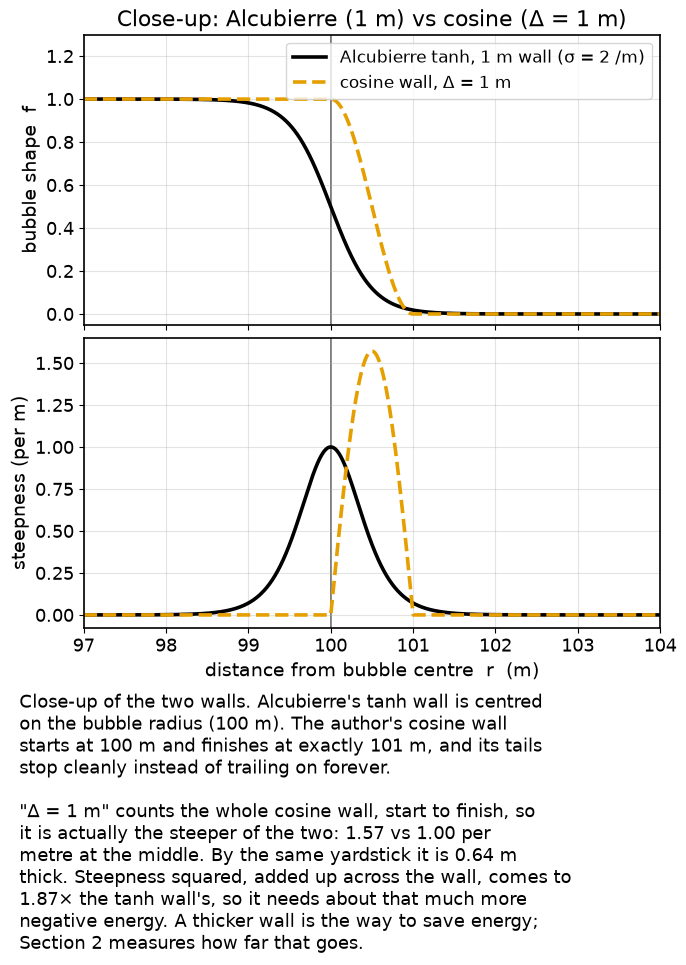

saved 01b_one_metre_walls.png


In [6]:
rz = np.linspace(97.0, 104.0, 7001)
fig, (ax_f, ax_df) = phone_figure(2, height_per_row=3.4, sharex=True)

pairs = [("Alcubierre tanh, 1 m wall (σ = 2 /m)", COLORS["black"], LINESTYLES[0],
          shapes.alcubierre_f(rz, R, SIGMA), shapes.alcubierre_df(rz, R, SIGMA)),
         ("cosine wall, Δ = 1 m", COLORS["orange"], LINESTYLES[1],
          shapes.cosine_wall_f(rz, R, 1.0), shapes.cosine_wall_df(rz, R, 1.0))]
for label, color, ls, f, df in pairs:
    ax_f.plot(rz, f, color=color, ls=ls, label=label)
    ax_df.plot(rz, -df, color=color, ls=ls)

for ax in (ax_f, ax_df):
    ax.axvline(R, color="0.4", lw=1.2, zorder=0)
ax_f.set_ylabel("bubble shape  f")
ax_f.set_ylim(-0.05, 1.3)
ax_f.set_title("Close-up: Alcubierre (1 m) vs cosine (Δ = 1 m)")
ax_f.legend(loc="upper right")
ax_df.set_ylabel("steepness (per m)")
ax_df.set_xlabel("distance from bubble centre  r  (m)")
ax_df.set_xlim(97, 104)

path = save_figure(fig, "01b_one_metre_walls", f'''
Close-up of the two walls. Alcubierre's tanh wall is centred on the bubble radius (100 m). The author's cosine wall starts at 100 m and finishes at exactly 101 m, and its tails stop cleanly instead of trailing on forever.

"Δ = 1 m" counts the whole cosine wall, start to finish, so it is actually the steeper of the two: 1.57 vs 1.00 per metre at the middle. By the same yardstick it is {shapes.cosine_wall_pf_thickness(1.0):.2f} m thick. Steepness squared, added up across the wall, comes to {COST_RATIO:.2f}× the tanh wall's, so it needs about that much more negative energy. A thicker wall is the way to save energy; Section 2 measures how far that goes.
''')
plt.show()
print("saved", path.name)

**What this section shows.** Both walls take the bubble from "inside" (f = 1) to "ordinary space" (f = 0). The author's cosine wall does it with a clean start and finish, and it can be stretched to any thickness. Making it 1000× thicker makes it 1000× less steep, and steepness is what the negative energy depends on. His formula for the steepest slope, π/(2Δ), is exactly right.

Measured fairly, the author's Δ = 1 m wall is a little *thinner* than Alcubierre's 1 m wall (0.64 m on the standard yardstick), so it costs nearly twice as much. That's a labelling difference, not a flaw: the idea is about making the wall thick, and the cosine shape lets you do that cleanly.

One thing to keep in mind for the next section: the author's wall grows *outward* from R, so a 1000 m wall reaches out to 1100 m. A thicker wall is gentler, but it also fills a lot more space. Section 2 adds up the energy over all of that space to see which effect wins.

## 2. How much negative energy? Total energy vs. wall thickness

The energy density goes as steepness squared, so a wall 1000× thicker has an energy density 1,000,000× lower. That's the author's estimate. But a thicker wall also takes up more space, so to get the *total* we have to add up the energy in every cubic metre of the wall. Here we do that for the author's cosine wall, at thicknesses from 1 mm to 100 km, with R = 100 m and the bubble moving at the speed of light.

**The formula, in ordinary units.** The energy density is

  T⁰⁰ = −(c⁴ / 8πG) · (v_s² / 4c²) · ((y² + z²) / r_s²) · (df/dr_s)²

The author's notes write v_s²/4, as Alcubierre's paper does. Both work in units where c = 1. In metres and seconds it becomes v_s²/(4c²), which is what we use. We report the total as a mass, E/c² in kilograms. At speeds other than light speed, multiply every result by (v_s/c)². For example, v_s = 10c means v_s² = 100c², so the energy is 100× larger.

**How we add it up, three independent ways.** (1) The full integral over all of space, done in cylindrical coordinates as the spec asks. (2) A 1-D shortcut: do the angle part by hand (Pfenning & Ford eq. 26) and integrate over radius only. (3) An exact formula for the author's wall, worked out by hand:

  ∫ r² (df/dr)² dr = (π²/8)·R²/Δ + (π²/8)·R + (π²/24 − 1/16)·Δ

If all three agree, we can trust the numbers.

In [7]:
from warp import energy
from warp.plotting import sci_text
from scipy.constants import c

BETA = 1.0                              # v_s / c  (bubble at light speed)
SPEED_TEXT = "light speed" if BETA == 1 else f"v_s = {BETA:g}c"
deltas = np.logspace(-3, 5, 49)         # wall thickness Δ: 1 mm to 100 km

def cos_df(d):
    return lambda x: shapes.cosine_wall_df(x, R, d)

mass_2d = np.array([energy.total_mass_cylindrical(cos_df(d), R, R + d, BETA) for d in deltas])
mass_1d = np.array([energy.mass_from_wall_integral(energy.wall_integral(cos_df(d), R, R + d), BETA) for d in deltas])
mass_exact = energy.mass_from_wall_integral(energy.cosine_wall_integral_exact(R, deltas), BETA)

print(f"largest disagreement, full integral vs exact formula: {np.max(np.abs(mass_2d / mass_exact - 1)):.1e}")
print(f"largest disagreement, 1-D shortcut  vs exact formula: {np.max(np.abs(mass_1d / mass_exact - 1)):.1e}")

largest disagreement, full integral vs exact formula: 3.9e-13
largest disagreement, 1-D shortcut  vs exact formula: 7.7e-12


**Checking against published results.** Before trusting the method on the author's wall, we run it on walls whose answers are already known.

In [8]:
def show(label, kg):
    print(f"{label:<52} {abs(kg):.3e} kg  = {abs(kg) / energy.M_SUN:.3f} solar masses")

ramp = energy.wall_integral(lambda x: shapes.pf_ramp_df(x, R, 1.0), R - 0.5, R + 0.5)
show("Pfenning & Ford straight wall, Δ = 1 m (our integral)", energy.mass_from_wall_integral(ramp, BETA))
show("Pfenning & Ford eq. 28, same wall (their formula)", energy.mass_from_wall_integral(R**2 / 1.0 + 1.0 / 12, BETA))
tanh_1m = energy.total_mass_cylindrical(lambda x: shapes.alcubierre_df(x, R, SIGMA), R - 30, R + 30, BETA)
show("Alcubierre tanh wall, 1 m (full integral)", tanh_1m)
show("cosine wall, Δ = 1 m (full integral)", energy.total_mass_cylindrical(cos_df(1.0), R, R + 1, BETA))

Pfenning & Ford straight wall, Δ = 1 m (our integral) 1.122e+30 kg  = 0.564 solar masses
Pfenning & Ford eq. 28, same wall (their formula)    1.122e+30 kg  = 0.564 solar masses


Alcubierre tanh wall, 1 m (full integral)            7.481e+29 kg  = 0.376 solar masses
cosine wall, Δ = 1 m (full integral)                 1.398e+30 kg  = 0.703 solar masses


Our integral reproduces Pfenning & Ford's own eq. 28 exactly. Their text says "on the order of a quarter of a solar mass", while eq. 28 gives 0.56, a factor of about 2. A guess at the cause: dividing by the Sun's Schwarzschild radius (2GM/c²) instead of GM/c² would give exactly 0.28. Either way it's the same order of magnitude, which is all they claimed. The 1 m cosine wall needs about 1.9× the tanh wall's energy, as Section 1 found.

Now the main question: how does the total change as the wall gets thicker?

In [9]:
# Slopes on the log-log plot: d ln|M| / d ln Δ
log_d, log_m = np.log10(deltas), np.log10(np.abs(mass_2d))
SLOPE_THIN = np.polyfit(log_d[deltas <= 0.1], log_m[deltas <= 0.1], 1)[0]
SLOPE_THICK = np.polyfit(log_d[deltas >= 1e4], log_m[deltas >= 1e4], 1)[0]
D_BEST = energy.cosine_wall_optimal_delta(R)
M_BEST = abs(energy.mass_from_wall_integral(energy.cosine_wall_integral_exact(R, D_BEST), BETA))
M_1M = abs(energy.mass_from_wall_integral(energy.cosine_wall_integral_exact(R, 1.0), BETA))

print(f"slope for thin walls  (Δ ≤ 0.1 m):  {SLOPE_THIN:+.3f}")
print(f"slope for thick walls (Δ ≥ 10 km):  {SLOPE_THICK:+.3f}")
print(f"lowest energy at Δ = {D_BEST:.1f} m: {M_BEST:.3e} kg = {M_BEST / energy.M_SUN:.4f} solar masses "
      f"= {M_BEST / energy.M_JUPITER:.1f} Jupiter masses")
print(f"that is {M_1M / M_BEST:.1f}× less than the 1 m wall")

slope for thin walls  (Δ ≤ 0.1 m):  -1.000
slope for thick walls (Δ ≥ 10 km):  +0.987
lowest energy at Δ = 188.1 m: 2.857e+28 kg = 0.0144 solar masses = 15.0 Jupiter masses
that is 49.0× less than the 1 m wall


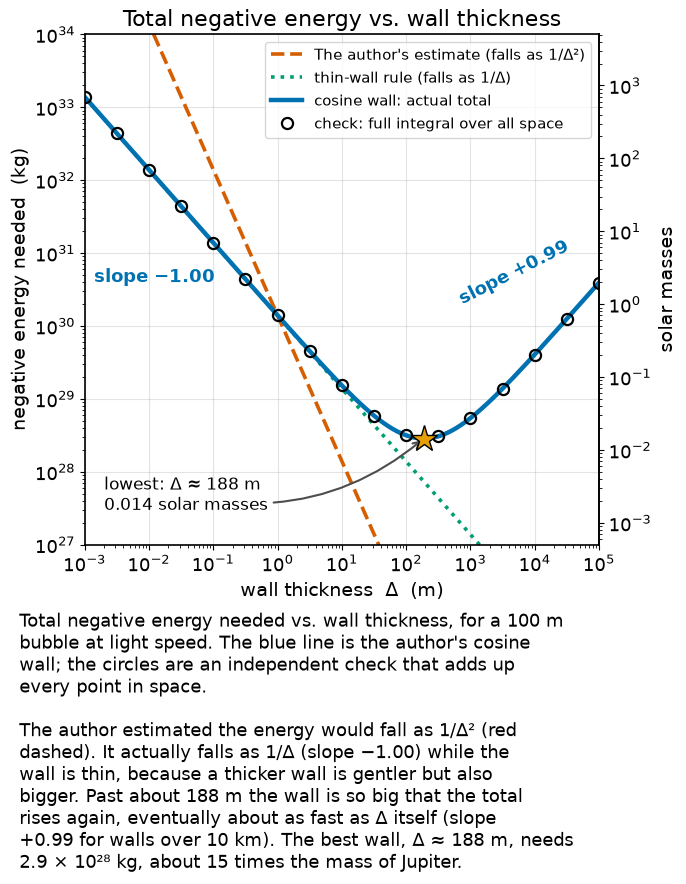

saved 02_energy_vs_thickness.png


In [10]:
d_fine = np.logspace(-3, 5, 801)
m_fine = np.abs(energy.mass_from_wall_integral(energy.cosine_wall_integral_exact(R, d_fine), BETA))
thin_rule = np.abs(energy.mass_from_wall_integral(np.pi**2 / 8 * R**2 / d_fine, BETA))   # (π²/8) R²/Δ

fig, ax = phone_figure(1, height_per_row=6.0)
ax.loglog(d_fine, M_1M / d_fine**2, color=COLORS["vermillion"], ls="--", label="The author's estimate (falls as 1/Δ²)")
ax.loglog(d_fine, thin_rule, color=COLORS["green"], ls=":", label="thin-wall rule (falls as 1/Δ)")
ax.loglog(d_fine, m_fine, color=COLORS["blue"], ls="-", lw=3.2, label="cosine wall: actual total")
ax.loglog(deltas[::3], np.abs(mass_2d[::3]), "o", color="black", mfc="none", ms=8, mew=1.6,
          label="check: full integral over all space")
ax.plot(D_BEST, M_BEST, marker="*", ms=20, color=COLORS["orange"], mec="black", zorder=5)
ax.annotate(f"lowest: Δ ≈ {D_BEST:.0f} m\n{M_BEST / energy.M_SUN:.3f} solar masses",
            (D_BEST, M_BEST), xytext=(2e-3, 3e27), textcoords="data", ha="left", fontsize=12,
            arrowprops=dict(arrowstyle="->", color="0.3", lw=1.5, connectionstyle="arc3,rad=0.25"))
ax.text(1.4e-3, 4e30, f"slope {SLOPE_THIN:.2f}".replace("-", "−"), fontsize=13, color=COLORS["blue"],
        fontweight="bold")
ax.text(6e2, 2.0e30, f"slope +{SLOPE_THICK:.2f}", fontsize=13, color=COLORS["blue"], fontweight="bold", rotation=27)

ax.set_xlim(1e-3, 1e5)
ax.set_ylim(1e27, 1e34)
ax.set_xlabel("wall thickness  Δ  (m)")
ax.set_ylabel("negative energy needed  (kg)")
ax.set_title("Total negative energy vs. wall thickness")
ax.legend(loc="upper right", fontsize=11)
sec = ax.secondary_yaxis("right", functions=(lambda m: m / energy.M_SUN, lambda s: s * energy.M_SUN))
sec.set_ylabel("solar masses")

path = save_figure(fig, "02_energy_vs_thickness", f'''
Total negative energy needed vs. wall thickness, for a 100 m bubble at light speed. The blue line is the author's cosine wall; the circles are an independent check that adds up every point in space.

The author estimated the energy would fall as 1/Δ² (red dashed). It actually falls as 1/Δ (slope −{abs(SLOPE_THIN):.2f}) while the wall is thin, because a thicker wall is gentler but also bigger. Past about {D_BEST:.0f} m the wall is so big that the total rises again, eventually about as fast as Δ itself (slope +{SLOPE_THICK:.2f} for walls over 10 km). The best wall, Δ ≈ {D_BEST:.0f} m, needs {sci_text(M_BEST)} kg, about {M_BEST / energy.M_JUPITER:.0f} times the mass of Jupiter.
''')
plt.show()
print("saved", path.name)

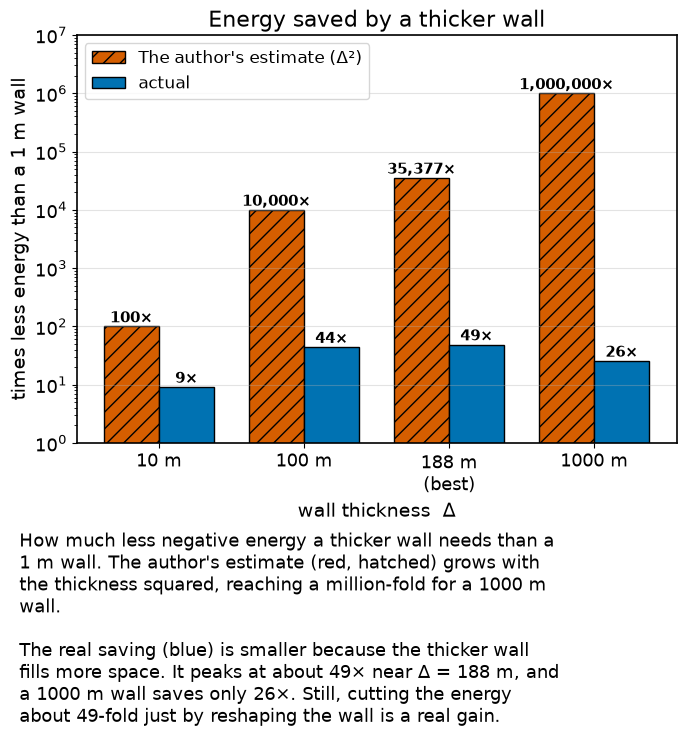

saved 02b_savings_vs_estimate.png


In [11]:
compare = [10.0, 100.0, D_BEST, 1000.0]
labels = ["10 m", "100 m", f"{D_BEST:.0f} m\n(best)", "1000 m"]
estimate_saving = np.array([d**2 for d in compare])          # The author's 1/Δ² estimate, relative to 1 m
actual_saving = np.array([M_1M / abs(energy.mass_from_wall_integral(energy.cosine_wall_integral_exact(R, d), BETA))
                          for d in compare])

fig, ax = phone_figure(1, height_per_row=5.2)
x = np.arange(len(compare))
w = 0.38
b1 = ax.bar(x - w / 2, estimate_saving, w, color=COLORS["vermillion"], hatch="//", edgecolor="black",
            label="The author's estimate (Δ²)")
b2 = ax.bar(x + w / 2, actual_saving, w, color=COLORS["blue"], edgecolor="black", label="actual")
for bars in (b1, b2):
    for bar in bars:
        v = bar.get_height()
        ax.annotate(f"{v:,.0f}×", (bar.get_x() + bar.get_width() / 2, v), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=11, fontweight="bold")
ax.set_yscale("log")
ax.set_ylim(1, 1e7)
ax.set_xticks(x, labels)
ax.set_xlabel("wall thickness  Δ")
ax.set_ylabel("times less energy than a 1 m wall")
ax.set_title("Energy saved by a thicker wall")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)

path = save_figure(fig, "02b_savings_vs_estimate", f'''
How much less negative energy a thicker wall needs than a 1 m wall. The author's estimate (red, hatched) grows with the thickness squared, reaching a million-fold for a 1000 m wall.

The real saving (blue) is smaller because the thicker wall fills more space. It peaks at about {actual_saving[2]:.0f}× near Δ = {D_BEST:.0f} m, and a 1000 m wall saves only {actual_saving[3]:.0f}×. Still, cutting the energy about {actual_saving[2]:.0f}-fold just by reshaping the wall is a real gain.
''')
plt.show()
print("saved", path.name)

**The answer, in two sentences.** The energy *density* does fall as 1/Δ², just as the author said, but a thicker wall also fills more space: while the wall is thinner than the bubble, its volume grows as Δ, so the total falls only as 1/Δ (Pfenning & Ford's result, slope −1). Because the author's wall grows outward from the bubble, once it is thicker than the bubble itself its volume grows faster than the density falls, so the total bottoms out near Δ ≈ 1.9 R (188 m for this bubble) and then climbs, eventually about as fast as Δ itself.

**What holds up.** For the *total amount* of negative energy, thickening the wall helps, up to about the bubble's own size. The best cosine wall needs about 49× less than a 1 m wall. The sweet spot scales with the bubble: Δ_best ≈ 1.88 R.

**What this section does not cover.**
- *Steady bubble.* These numbers are for a bubble at constant speed. The energy-density formula itself still holds at every instant for the author's time-dependent designs (it depends only on how the bubble's shape varies in space), but those designs change the stresses and the curvature of space-time, which a later section works out.
- *The quantum inequality points the other way.* Pfenning & Ford's main objection isn't the total amount. It's how strong negative energy can be and for how long, the author's |ρ|·τ⁴ ≤ constant. A thicker wall lowers the strength |ρ| (as 1/Δ²), but it also bends space more gently, and the time window the test is allowed to use grows with the bending length (τ grows as Δ). So |ρ|·τ⁴ *grows* as Δ². By their test a thick wall is harder to allow, not easier. That is how they conclude the wall can be at most about 100 Planck lengths thick (their eq. 23). Whether their assumptions hold for a real warp drive (a free scalar field, and their choice of how long to sample the energy) is the genuine open question, and a good one for the author to dig into. Section 3 puts numbers on it.

In [12]:
# The author's notes quote E ≈ −10⁴⁵ kg. What would it take to get that with this formula?
target = 1e45
k = energy.KG_PER_METRE / 12 * BETA**2 * np.pi**2 / 8 * R**2   # thin-wall rule at this speed: M ≈ k / Δ
print(f"at {SPEED_TEXT}, a cosine wall would need Δ ≈ {k / target:.1e} m to reach 10^45 kg")
print(f"with a 1 m wall, it would need v_s ≈ {BETA * np.sqrt(target / M_1M):.1e} c")   # M ∝ v_s²
print(f"for comparison: 10^45 joules is a mass of {1e45 / c**2:.1e} kg; this section's best wall needs {M_BEST:.1e} kg")

at light speed, a cosine wall would need Δ ≈ 1.4e-15 m to reach 10^45 kg
with a 1 m wall, it would need v_s ≈ 2.7e+07 c
for comparison: 10^45 joules is a mass of 1.1e+28 kg; this section's best wall needs 2.9e+28 kg


**About the −10⁴⁵ kg figure in the author's notes.** With a 100 m bubble, that much energy would need either a wall about 10⁻¹⁵ m thin (roughly the size of a proton) or a speed of tens of millions of times light speed. We don't know which assumptions went into that number, so it's a good question to ask the author. Two possibilities worth asking about, both guesses:
- Pfenning & Ford quote the Milky Way's mass as "2 × 10⁴⁵ **grams**" (their eq. 30). Grams vs. kilograms is an easy slip.
- 10⁴⁵ **joules** is about 1 × 10²⁸ kg, close to this section's best-wall answer (2.9 × 10²⁸ kg). Joules vs. kilograms is another easy slip.

It may also come from a different bubble size, speed or wall thickness than the ones used here.

## 3. The quantum inequality: how long can negative energy last?

Quantum physics does allow negative energy, but with a catch: the stronger it is, the shorter it can last. The author's notes write this as |ρ|·τ⁴ ≤ constant, and that is exactly the right form: it is the Ford–Roman *quantum inequality*. Here we put in the real constant and test the cosine wall against it. This is the test Pfenning & Ford used to argue that warp-bubble walls must be fantastically thin.

**The rule.** For the simplest quantum field, a negative energy density of strength |ρ| can last only about τ, where

  |ρ| · τ⁴ ≤ 3ħ / (32π² c³) ≈ 3.7 × 10⁻⁶² J·s⁴/m³

(ħ is the reduced Planck constant.) Strictly, it limits the energy density averaged over a time window of width τ, as seen by someone floating past.

**The catch for curved space.** The rule was proven for flat space. Near a warp-bubble wall, space is curved, so the rule is only trusted over time windows shorter than the time light takes to cross the curvature length r_min (the shortest bending length of space-time anywhere in the wall). Following Pfenning & Ford we use a window of τ = α·r_min/c with α = 0.1.

**How we test, step by step.**
1. Find the strongest negative energy anywhere in the wall (on the bubble's "equator", where the wall is steepest).
2. Compute r_min from the *full* curvature of space-time, all 20 independent components of the Riemann tensor, everywhere in the wall (`warp/curvature.py`).
3. Follow a real observer drifting through the strongest spot, and average the energy they see over the window τ, exactly as the rule prescribes.
4. Compare with the most negative average the rule allows.

**The choices favour the warp design.** For r_min we take the largest curvature *anywhere* in the wall, even at points the observer never visits. That gives the shortest window, and a shorter window loosens the limit. Pfenning & Ford used one curvature component of a simplified straight wall. Our worst-case choice is about 7× looser than their estimate. Using only the curvature along the observer's own path would be about 1.7× looser than theirs. The next cell prints both, and the headline numbers use the looser one.

In [13]:
from warp import quantum

print(f"quantum-inequality constant 3ħ/(32π²c³) = {quantum.QI_CONSTANT:.3e} J·s⁴/m³")
print(f"Planck length = {quantum.PLANCK_LENGTH:.4e} m\n")

ALPHA = 0.1
def cos_funcs(d):
    return (lambda x: shapes.cosine_wall_f(x, R, d), lambda x: shapes.cosine_wall_df(x, R, d),
            lambda x: shapes.cosine_wall_ddf(x, R, d))

qi = {d: quantum.qi_check(BETA, ALPHA, *cos_funcs(d), R, R + d) for d in [1.0, D_BEST, 1000.0]}
print(f"{'wall Δ':>9} {'strongest |ρ| (J/m³)':>21} {'may last':>10} {'test window':>12} {'over the limit by':>18}")
for d, res in qi.items():
    print(f"{d:>7.0f} m {abs(res.peak_density):>21.2e} {res.allowed_duration:>8.1e} s {res.tau:>10.1e} s {res.violation:>18.1e}")

w1 = quantum.qi_check(BETA, ALPHA, *cos_funcs(1.0), R, R + 1.0, curvature="worldline")
print(f"\n1 m wall using only the curvature along the observer's path: over the limit by {w1.violation:.1e} "
      f"({w1.violation / qi[1.0].violation:.1f}× tighter than the worst-case choice above)")

quantum-inequality constant 3ħ/(32π²c³) = 3.718e-62 J·s⁴/m³
Planck length = 1.6163e-35 m



   wall Δ  strongest |ρ| (J/m³)   may last  test window  over the limit by
      1 m              2.97e+42  1.1e-26 s    1.5e-10 s            4.1e+64
    188 m              8.40e+37  1.5e-25 s    2.8e-08 s            1.4e+69
   1000 m              2.97e+36  3.3e-25 s    1.5e-07 s            3.9e+70

1 m wall using only the curvature along the observer's path: over the limit by 1.7e+65 (4.1× tighter than the worst-case choice above)


**Reading the table.** For a 1 m wall the negative energy is so strong that the rule lets it last only about 10⁻²⁶ seconds. But the wall holds it in place for the whole test window, about 10⁻¹⁰ seconds (and in fact much longer, the whole time the bubble takes to pass). Because the limit goes as τ⁴, a factor of about 10¹⁶ in time becomes a factor of about 10⁶⁴ in the inequality. Thicker walls make it worse, not better: they lower the strength (as 1/Δ²) but stretch the window (as Δ), so the overshoot grows as Δ².

The next cell checks how much these conclusions depend on the choices we made: the window size α and the bubble's speed.

In [14]:
f1, df1, ddf1 = cos_funcs(1.0)
print("1 m cosine wall, how far over the limit:")
for beta in [1.0, 10.0]:
    row = "  ".join(f"α = {a:<4g}: {quantum.qi_check(beta, a, f1, df1, ddf1, R, R + 1.0).violation:.1e}"
                    for a in [1.0, 0.1, 0.01])
    print(f"  v_s = {beta:>4g} c   {row}")

v_needed = BETA * np.sqrt(qi[1.0].violation)   # overshoot falls as 1/(v_s/c)²
d_ok = 1.0 / np.sqrt(qi[1.0].violation)      # overshoot grows as Δ²; Δ = 1 m is the reference
print(f"\nto pass (at α = {ALPHA:g}), a 1 m wall would need v_s ≈ {v_needed:.0e} c,")
print(f"or, at v_s = c, a wall thinner than about {d_ok:.0e} m = {d_ok / quantum.PLANCK_LENGTH:.0f} Planck lengths")

1 m cosine wall, how far over the limit:


  v_s =    1 c   α = 1   : 4.0e+68  α = 0.1 : 4.1e+64  α = 0.01: 4.1e+60


  v_s =   10 c   α = 1   : 4.0e+66  α = 0.1 : 4.1e+62  α = 0.01: 4.1e+58

to pass (at α = 0.1), a 1 m wall would need v_s ≈ 2e+32 c,
or, at v_s = c, a wall thinner than about 5e-33 m = 307 Planck lengths


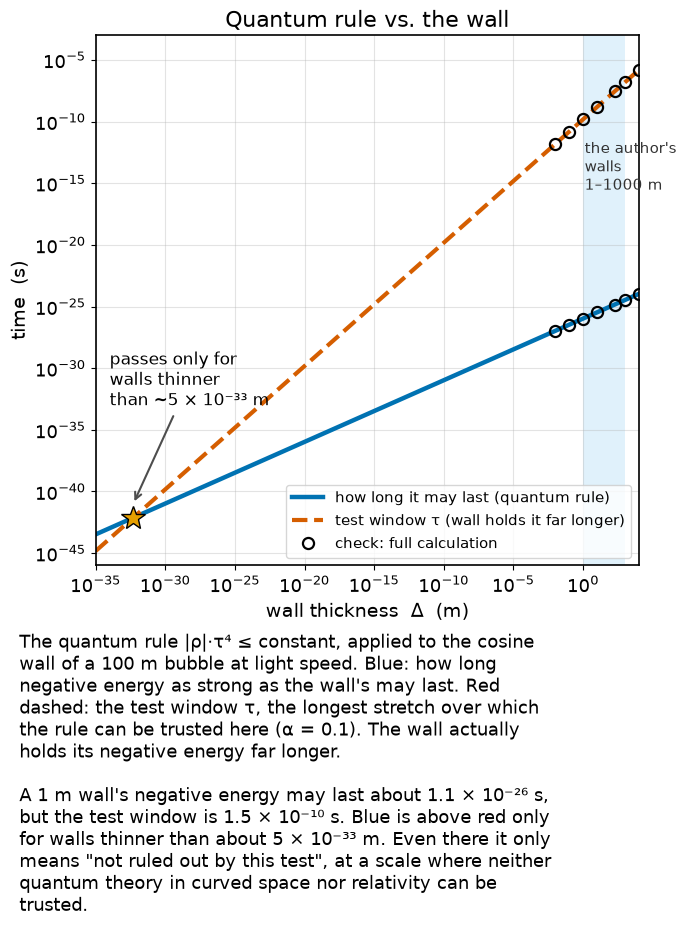

saved 03_quantum_inequality.png


In [15]:
# Durations vs wall thickness. Both are exact formulas for the cosine wall, valid at any Δ:
#   strongest |ρ| = (c⁴/8πG)(β²/4)(π/2Δ)²   (equator, mid-wall)
#   r_min = 1/√(β² π²/(2Δ²))                 (largest curvature: on the axis at the outer edge;
#                                             tested for β ≥ 0.5, and scale-free because f = f' = 0 there)
# Circles: the full numerical calculation at a few thicknesses, as a check.
from scipy.constants import c as C_LIGHT

d_axis = np.logspace(-35, 4, 400)
rho_peak = energy.ENERGY_DENSITY_SCALE * BETA**2 / 4 * (np.pi / (2 * d_axis))**2
may_last = quantum.allowed_duration(rho_peak)
window = ALPHA * np.sqrt(2) * d_axis / (np.pi * BETA) / C_LIGHT
D_OK = d_ok

check_d = [1e-2, 1e-1, 1.0, 10.0, D_BEST, 1e3, 1e4]
checks = [quantum.qi_check(BETA, ALPHA, *cos_funcs(d), R, R + d) for d in check_d]

fig, ax = phone_figure(1, height_per_row=6.2)
ax.loglog(d_axis, may_last, color=COLORS["blue"], lw=3.2, label="how long it may last (quantum rule)")
ax.loglog(d_axis, window, color=COLORS["vermillion"], ls="--", lw=3.0, label="test window τ (wall holds it far longer)")
ax.loglog(check_d, [r.allowed_duration for r in checks], "o", color="black", mfc="none", ms=8, mew=1.6,
          label="check: full calculation")
ax.loglog(check_d, [r.tau for r in checks], "o", color="black", mfc="none", ms=8, mew=1.6)
ax.plot(D_OK, quantum.allowed_duration(energy.ENERGY_DENSITY_SCALE * BETA**2 / 4 * (np.pi / (2 * D_OK))**2), marker="*",
        ms=18, color=COLORS["orange"], mec="black", zorder=5)
ax.annotate(f"passes only for\nwalls thinner\nthan ~{sci_text(D_OK, 0)} m", (D_OK, 1e-41), xytext=(1e-34, 1e-33),
            fontsize=12, arrowprops=dict(arrowstyle="->", color="0.3", lw=1.5))
ax.axvspan(1.0, 1e3, color=COLORS["sky"], alpha=0.18, lw=0)
ax.text(1.3, 3e-16, "the author's\nwalls\n1–1000 m", fontsize=11, color="0.2")

ax.set_xlim(1e-35, 1e4)
ax.set_ylim(1e-46, 1e-3)
ax.set_xlabel("wall thickness  Δ  (m)")
ax.set_ylabel("time  (s)")
ax.set_title("Quantum rule vs. the wall")
ax.legend(loc="lower right", fontsize=11)

path = save_figure(fig, "03_quantum_inequality", f'''
The quantum rule |ρ|·τ⁴ ≤ constant, applied to the cosine wall of a 100 m bubble at {SPEED_TEXT}. Blue: how long negative energy as strong as the wall's may last. Red dashed: the test window τ, the longest stretch over which the rule can be trusted here (α = {ALPHA:g}). The wall actually holds its negative energy far longer.

A 1 m wall's negative energy may last about {sci_text(qi[1.0].allowed_duration)} s, but the test window is {sci_text(qi[1.0].tau)} s. Blue is above red only for walls thinner than about {sci_text(D_OK, 0)} m. Even there it only means "not ruled out by this test", at a scale where neither quantum theory in curved space nor relativity can be trusted.
''')
plt.show()
print("saved", path.name)

**What holds up.**
- The author's form of the rule, |ρ|·τ⁴ ≤ constant, is exactly right; the constant is 3ħ/(32π²c³).
- The pulsed design was aimed at the right weak spot. The rule *does* allow stronger negative energy for shorter times, so "keep each burst brief" is the natural move. The numbers are extreme: a burst as strong as this 1 m wall's negative energy would have to be over within about 10⁻²⁶ seconds. Switching on and off also bends space-time in its own way, which changes the test window and brings requirements of its own. So the pulsed and dual-shell designs need their own analysis, which comes in a later section.

**What the numbers say.** By this test a thick wall is harder to allow, not easier. The overshoot grows as Δ², from about 10⁶⁴ at 1 m to about 10⁷⁰ at 1000 m. Sections 2 and 3 pull in opposite directions: thicker walls need less total negative energy, while the quantum rule demands thinner ones. That tension is Pfenning & Ford's whole argument.

**What is still genuinely open.** The rule used here holds for *every* quantum state of the simplest kind of field (a free scalar field), so choosing a clever state doesn't escape it. What is genuinely open:
1. Fields with interactions, or unusual couplings to gravity. Some of these are known to get around the simplest versions of these rules.
2. How the rule itself changes in strongly curved space. Here we assumed the flat-space version holds over windows shorter than the curvature time, as Pfenning & Ford did.
3. Whether the whole picture, quantum fields living on a classical curved space-time, still holds near the Planck scale.

That is where a new idea would have to break through, and it's a great set of questions to dig into.

## 4. The dual-shell "always on" design

The author's current design uses two nested shells, at 100 m and 90 m, driven by a cosine and a sine at 1 GHz, so that as one fades the other takes over. Here we code the formula exactly as written, watch it through one cycle, and check four things: which way each shell faces, the timing between them, whether the ship actually goes anywhere, and whether the negative energy stays constant.

The formula, as written in the notes:

  f_total(r, t) = ½[1 + tanh(2.0(r − 100))]·cos(ωt) + ½[1 − tanh(2.0(r − 90))]·sin(ωt),  ω = 2π × 1 GHz

One cycle lasts 1 nanosecond. We use v_s = c throughout; distances moved scale with v_s, and energies with v_s².

**Two facts we lean on.** First, anything that starts at rest in the local "flow" of space keeps moving with it, freely, at speed v_s·f, with f taken wherever the object is at that moment (true even when f changes in time, because these observers are in free fall). So the ship at the centre moves at v_s·f(0, t), and distant stars at v_s·f(far away, t).

**Where the bubble goes.** The notes don't say how the bubble's centre moves in this design. We use Alcubierre's rule, which keeps the ship at the centre: the centre moves with the flow there. With cos/sin drives the whole bubble then rocks back and forth together with the ship. (If the centre instead marched steadily forward at v_s, the walls would drift away and leave the ship behind after a few hundred cycles; the ship would be nudged a few centimetres as a wall swept past and then stay put. Either way it doesn't travel.) Second, the energy-density formula from Section 2 still holds at every instant (checked symbolically in `warp/curvature.py`), so we can add up the energy at each moment just as before.

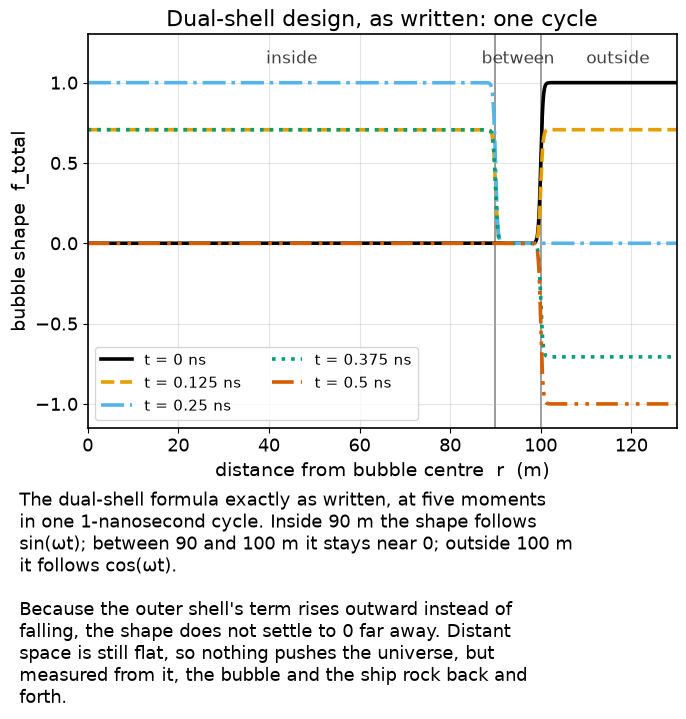

saved 04_dual_shell_as_written.png


In [16]:
from warp import dual_shell as ds

AS_WRITTEN = ds.VARIANTS["as written"]
T_CYCLE = ds.period(AS_WRITTEN)
r_ds = np.linspace(0.0, 130.0, 13_001)
snap_fracs = [0.0, 0.125, 0.25, 0.375, 0.5]
snap_style = [(COLORS["black"], LINESTYLES[0]), (COLORS["orange"], LINESTYLES[1]), (COLORS["sky"], LINESTYLES[2]),
              (COLORS["green"], LINESTYLES[3]), (COLORS["vermillion"], LINESTYLES[4])]

fig, ax = phone_figure(1, height_per_row=4.8)
for frac, (col, ls) in zip(snap_fracs, snap_style):
    ax.plot(r_ds, shapes.dual_shell_f(r_ds, frac * T_CYCLE, **AS_WRITTEN), color=col, ls=ls,
            label=f"t = {frac * T_CYCLE * 1e9:.3g} ns")
for R_shell in (90, 100):
    ax.axvline(R_shell, color="0.5", lw=1.1, zorder=0)
ax.text(45, 1.12, "inside", ha="center", fontsize=12, color="0.25")
ax.text(95, 1.12, "between", ha="center", fontsize=12, color="0.25")
ax.text(117, 1.12, "outside", ha="center", fontsize=12, color="0.25")
ax.set_xlim(0, 130)
ax.set_ylim(-1.15, 1.3)
ax.set_xlabel("distance from bubble centre  r  (m)")
ax.set_ylabel("bubble shape  f_total")
ax.set_title("Dual-shell design, as written: one cycle")
ax.legend(loc="lower left", fontsize=11, ncol=2)

path = save_figure(fig, "04_dual_shell_as_written", '''
The dual-shell formula exactly as written, at five moments in one 1-nanosecond cycle. Inside 90 m the shape follows sin(ωt); between 90 and 100 m it stays near 0; outside 100 m it follows cos(ωt).

Because the outer shell's term rises outward instead of falling, the shape does not settle to 0 far away. Distant space is still flat, so nothing pushes the universe, but measured from it, the bubble and the ship rock back and forth.
''')
plt.show()
print("saved", path.name)

### Check 1: which way each shell faces

½[1 + tanh(…)] climbs from 0 to 1 going *outward*, while ½[1 − tanh(…)] falls from 1 to 0. As written, the 100 m shell uses the climbing form and the 90 m shell the falling form, so they face opposite ways. That is why the chart above doesn't go to 0 far away. The spec's alternative makes both shells use ½[1 − tanh(…)], so both "switch on" inside their radius, like an ordinary bubble.

### Check 2: the timing between the shells (90° or 180°)

The formula uses cos and sin, which are 90° apart. The sketch says "180° out of phase." The chart below shows both, plus the alternative from Check 1 and one more alternative described in Check 3.

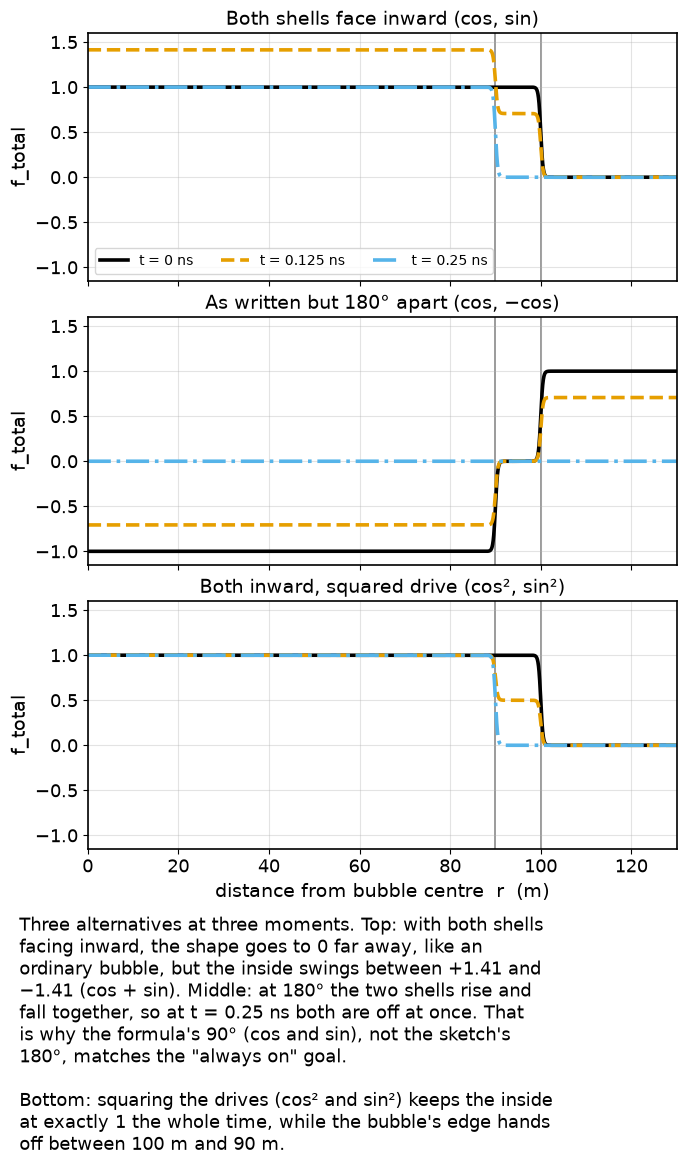

saved 04b_dual_shell_alternatives.png


In [17]:
alt_names = ["both shells face inward", "180° phase", "inward + squared drive"]
alt_titles = ["Both shells face inward (cos, sin)", "As written but 180° apart (cos, −cos)",
              "Both inward, squared drive (cos², sin²)"]
fig, axes = phone_figure(3, height_per_row=3.0, sharex=True)
for ax, name, title in zip(axes, alt_names, alt_titles):
    for frac, (col, ls) in zip([0.0, 0.125, 0.25], snap_style[:3]):
        ax.plot(r_ds, shapes.dual_shell_f(r_ds, frac * T_CYCLE, **ds.VARIANTS[name]), color=col, ls=ls,
                label=f"t = {frac * T_CYCLE * 1e9:.3g} ns")
    for R_shell in (90, 100):
        ax.axvline(R_shell, color="0.5", lw=1.1, zorder=0)
    ax.set_title(title, fontsize=14)
    ax.set_ylabel("f_total")
    ax.set_ylim(-1.15, 1.6)
axes[0].legend(loc="lower left", fontsize=10, ncol=3)
axes[-1].set_xlabel("distance from bubble centre  r  (m)")
axes[-1].set_xlim(0, 130)

path = save_figure(fig, "04b_dual_shell_alternatives", '''
Three alternatives at three moments. Top: with both shells facing inward, the shape goes to 0 far away, like an ordinary bubble, but the inside swings between +1.41 and −1.41 (cos + sin). Middle: at 180° the two shells rise and fall together, so at t = 0.25 ns both are off at once. That is why the formula's 90° (cos and sin), not the sketch's 180°, matches the "always on" goal.

Bottom: squaring the drives (cos² and sin²) keeps the inside at exactly 1 the whole time, while the bubble's edge hands off between 100 m and 90 m.
''')
plt.show()
print("saved", path.name)

### Check 3: does the ship go anywhere?

Cosine and sine are positive half the time and negative half the time. So whatever they drive moves forward for half a cycle and backward for the other half. Below we follow the ship (at the centre) relative to distant space through two cycles.

The "squared drive" is our suggestion, not something in the author's notes. It is one way to get steady motion: both shells face inward, and the drives are cos² and sin² instead of cos and sin. Those never go negative and always add up to 1, so the inside always has f = 1 and moves at the full v_s. It keeps the 90° timing and the two shells. In effect it is a single bubble whose edge slides back and forth between 100 m and 90 m. Note that cos² = ½(1 + cos 2ωt), so it actually switches at 2 GHz.

average speed of the ship relative to distant space, over one cycle:
  as written                 +0.0000 c
  both shells face inward    +0.0000 c
  180° phase                 +0.0000 c
  inward + squared drive     +1.0000 c

as written, the ship swings between -2.0 cm and +11.5 cm and returns


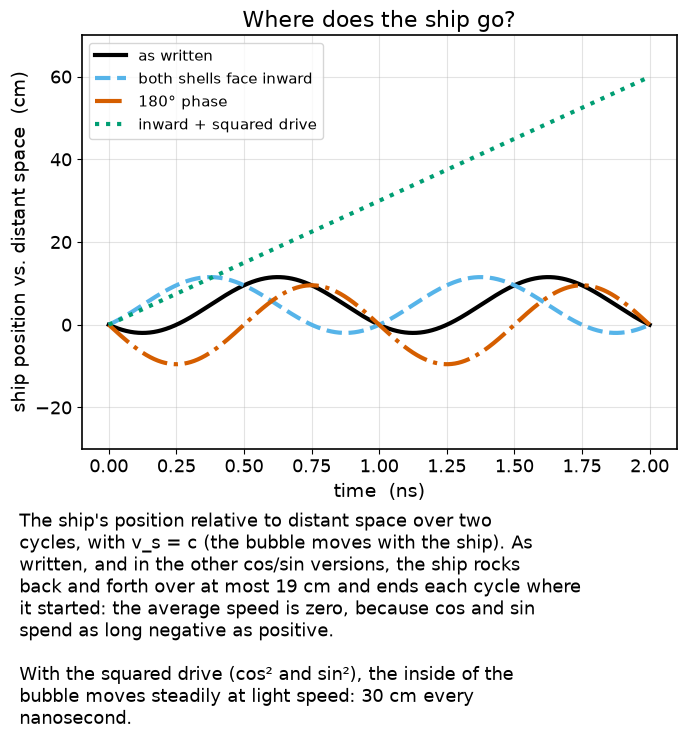

saved 04c_ship_motion.png


In [18]:
t_mot = np.linspace(0.0, 2 * T_CYCLE, 4001)
motion_style = {"as written": (COLORS["black"], "-"), "both shells face inward": (COLORS["sky"], "--"),
                "180° phase": (COLORS["vermillion"], "-."), "inward + squared drive": (COLORS["green"], ":")}

print("average speed of the ship relative to distant space, over one cycle:")
for name, p in ds.VARIANTS.items():
    print(f"  {name:<26} {ds.mean_relative_velocity(BETA, p):+.4f} c")

x_as = ds.relative_displacement(t_mot, BETA, AS_WRITTEN)
print(f"\nas written, the ship swings between {x_as.min() * 100:+.1f} cm and {x_as.max() * 100:+.1f} cm and returns")
swing_cm = max(np.ptp(ds.relative_displacement(t_mot, BETA, ds.VARIANTS[n])) * 100
               for n in ["as written", "both shells face inward", "180° phase"])

fig, ax = phone_figure(1, height_per_row=5.0)
for name, p in ds.VARIANTS.items():
    col, ls = motion_style[name]
    ax.plot(t_mot * 1e9, ds.relative_displacement(t_mot, BETA, p) * 100, color=col, ls=ls, lw=3, label=name)
ax.set_xlabel("time  (ns)")
ax.set_ylabel("ship position vs. distant space  (cm)")
ax.set_title("Where does the ship go?")
ax.set_ylim(-30, 70)
ax.legend(loc="upper left", fontsize=11)

path = save_figure(fig, "04c_ship_motion", f'''
The ship's position relative to distant space over two cycles, with v_s = c (the bubble moves with the ship). As written, and in the other cos/sin versions, the ship rocks back and forth over at most {swing_cm:.0f} cm and ends each cycle where it started: the average speed is zero, because cos and sin spend as long negative as positive.

With the squared drive (cos² and sin²), the inside of the bubble moves steadily at light speed: 30 cm every nanosecond.
''')
plt.show()
print("saved", path.name)

### Check 4: does the negative energy stay constant?

Each shell's negative energy goes as the square of its drive, so its size doesn't depend on whether the drive is positive or negative. The two shells sit at different radii (90 m and 100 m), and the energy of a shell scales with its area, about r². So even when the drives trade off perfectly, the total can slosh.

  as written                 min 6.06e+29 kg   max 7.48e+29 kg   average 6.77e+29 kg   swing ×1.23
  both shells face inward    min 6.06e+29 kg   max 7.48e+29 kg   average 6.77e+29 kg   swing ×1.23
  180° phase                 min ≈ 0 kg (bubble fully off)   max 1.35e+30 kg   average 6.77e+29 kg
  inward + squared drive     min 3.35e+29 kg   max 7.48e+29 kg   average 5.08e+29 kg   swing ×2.23

cheapest steady bubble with its edge split over both walls: 45% on the 100 m shell, 55% on the 90 m shell: 3.35e+29 kg, steady


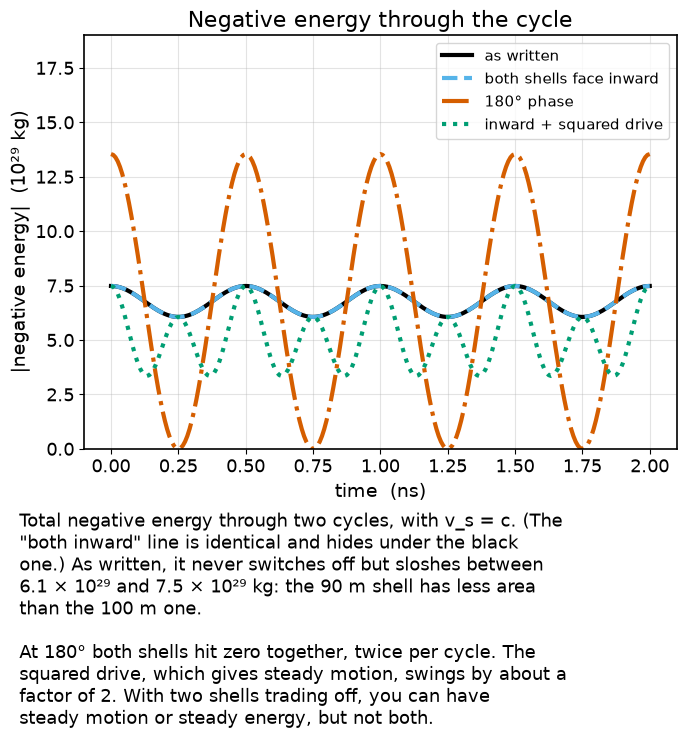

saved 04d_energy_over_time.png


In [19]:
t_en = np.linspace(0.0, 2 * T_CYCLE, 241)
masses = {name: -ds.mass_vs_time(t_en, BETA, p) for name, p in ds.VARIANTS.items()}
for name, m in masses.items():
    print(f"  {name:<26} min {m.min():.2e} kg   max {m.max():.2e} kg   average {m[:-1].mean():.2e} kg   swing ×{m.max() / m.min():.2f}"
          if m.min() > 1e-6 * m.max() else f"  {name:<26} min ≈ 0 kg (bubble fully off)   max {m.max():.2e} kg   average {m[:-1].mean():.2e} kg")

A_SPLIT, M_SPLIT = ds.cheapest_steady_split(ds.VARIANTS["both shells face inward"], BETA)
print(f"\ncheapest steady bubble with its edge split over both walls: {A_SPLIT:.0%} on the 100 m shell, "
      f"{1 - A_SPLIT:.0%} on the 90 m shell: {-M_SPLIT:.2e} kg, steady")

fig, ax = phone_figure(1, height_per_row=5.0)
for name, m in masses.items():
    col, ls = motion_style[name]
    ax.plot(t_en * 1e9, m / 1e29, color=col, ls=ls, lw=3, label=name)
ax.set_xlabel("time  (ns)")
ax.set_ylabel("|negative energy|  (10²⁹ kg)")
ax.set_title("Negative energy through the cycle")
ax.set_ylim(0, 19)
ax.legend(loc="upper right", fontsize=11)

e_as = masses["as written"]
path = save_figure(fig, "04d_energy_over_time", f'''
Total negative energy through two cycles, with v_s = c. (The "both inward" line is identical and hides under the black one.) As written, it never switches off but sloshes between {sci_text(e_as.min())} and {sci_text(e_as.max())} kg: the 90 m shell has less area than the 100 m one.

At 180° both shells hit zero together, twice per cycle. The squared drive, which gives steady motion, swings by about a factor of 2. With two shells trading off, you can have steady motion or steady energy, but not both.
''')
plt.show()
print("saved", path.name)

**Why steady motion and steady energy fight each other.** Call the two drive strengths a and b. With both shells facing inward, the inside of the bubble moves at v_s·(a + b), so steady motion needs a + b = 1. The energy goes as a²·E₁₀₀ + b²·E₉₀. If a and b keep trading off while a + b = 1, the energy must swing too. Picture it as a straight line (steady speed) crossing an oval (steady energy): they meet at no more than two points, so two drives can't keep moving and stay on both. This holds for any two shells whose walls don't overlap, as here (10 m apart, 1 m walls). The different radii are only why the *as-written* energy sloshes. Two shells at the *same* radius would simply act as one shell, and handing off between them would cost nothing. (This covers shells of fixed shape that are turned up and down, not walls that physically move.)

**But three shells could do it.** With three drives a, b, c, steady speed means a + b + c = 1 (a flat sheet) and steady energy means a²E₁ + b²E₂ + c²E₃ = constant (an egg-shaped surface). A flat sheet cuts an egg in a closed loop, and the drives can circle around that loop forever: every shell keeps changing, while speed and energy both stay exactly constant. (We checked this numerically for shells at 100, 90 and 80 m.) A three-shell handoff is a genuinely different design from the one in the notes, and it might be worth the author's time.

**A bonus from the same arithmetic.** If you *stop* trading off and keep both shells partly on, the cheapest split puts about 45% on the 100 m shell and 55% on the 90 m shell. That bubble is steady, moves at the full v_s, and needs about 3.4 × 10²⁹ kg: less than half of a single wall (7.5 × 10²⁹ kg), and less than any of the oscillating versions on average (see the printout above). Spreading the bubble's edge over more room lowers the energy, which is the author's thick-wall instinct showing up again.

**What holds up.**
- The formula's choice of cos and sin (90° apart) is the one that keeps at least one shell on at every moment; the sketch's "180°" would switch both off together. The math was right and the sketch was the slip.
- Comparing the switching rate with the time light takes to cross the wall (1 m / c ≈ 3.33 ns, so about 300 MHz) is good instinct: in relativity, how fast something changes is usually best judged against how fast light can cross it. The 1 GHz choice switches faster than that. Two related facts for the time-dependent section: at 1 GHz the drive changes over a light-distance of about 5 cm (ω/c ≈ 21 per metre), much shorter than the 1 m wall, so the switching, not the wall shape, will dominate the bending of space-time there. And light needs about 33 ns to cross the 10 m between the shells, so within one 1 ns cycle the two shells can't "see" each other.

**What the math does as written.** The outer shell faces the opposite way from the inner one, so measured from distant space the whole bubble rocks back and forth, and the ship rocks with it by a few centimetres without going anywhere. Both shells facing inward fixes the first two. Getting net motion needs drives whose average isn't zero. cos² and sin² are one example, at the cost of energy that swings by about 2×.

**Not covered here.** This section uses the instantaneous energy formula, which is exact. But a design that changes every nanosecond also changes the *stresses* in the wall and the bending of space-time, and with it the quantum-inequality test from Section 3. Those come in the time-dependent section.

## 5. Animation: the dual-shell bubble in motion

Here is the dual-shell design, exactly as written, as a moving picture: a slice through the middle of the bubble, coloured by how strong the negative energy is at each point. Watch the two rings take turns, the outer one fading as the inner one brightens, while the strip underneath shows the two drives that cause it.

The walls are only about 1 m thick in a bubble 200 m across, so in the full view they are thin lines. The close-up shows the top of the bubble, where both walls are easy to see. Every frame uses the same colour scale, so brightness can be compared from frame to frame.

**Checking the picture.** Before trusting the colours, we add up the energy in each frame's map (treating it as a slice of a bubble that is the same all the way around the line of travel) and compare with the totals from Section 4.

In [20]:
from warp import animate

frame_times = np.linspace(0.0, 2 * T_CYCLE, 60, endpoint=False)
worst = 0.0
for t in frame_times:
    xm, ym, rho_m = animate.energy_density_map(AS_WRITTEN, t, BETA)
    worst = max(worst, abs(animate.map_total_mass(xm, ym, rho_m) / ds.mass_vs_time([t], BETA, AS_WRITTEN)[0] - 1))
print(f"{len(frame_times)} frames: largest difference between a map's total and Section 4's total = {worst:.1e}")

60 frames: largest difference between a map's total and Section 4's total = 6.3e-07


In [21]:
ANIM_TITLE = "Dual-shell bubble, as written"
ANIM_CAPTION = '''
The dual-shell bubble exactly as written, sliced through the middle; brighter means stronger negative energy. The 100 m shell follows the cosine drive and the 90 m shell the sine, so one brightens as the other fades and the bubble is never fully off.

The glow is strongest above and below the ship and fades to nothing straight ahead and behind: the negative energy forms rings around the line of travel.
'''
gif_path, mp4_path = animate.save_animation(AS_WRITTEN, BETA, "05_dual_shell_animation", ANIM_TITLE, ANIM_CAPTION)
stills = [animate.save_still(AS_WRITTEN, BETA, frac * T_CYCLE, f"05{tag}_dual_shell_t{frac * T_CYCLE * 1e9:.3f}ns",
                             ANIM_TITLE, ANIM_CAPTION)
          for tag, frac in [("a", 0.0), ("b", 0.125), ("c", 0.25)]]
for p_ in [gif_path, mp4_path, *stills]:
    print(f"saved {p_.name}  ({p_.stat().st_size / 1e6:.1f} MB)")

saved 05_dual_shell_animation.gif  (3.4 MB)
saved 05_dual_shell_animation.mp4  (0.3 MB)
saved 05a_dual_shell_t0.000ns.png  (0.2 MB)
saved 05b_dual_shell_t0.125ns.png  (0.3 MB)
saved 05c_dual_shell_t0.250ns.png  (0.2 MB)


![The dual-shell bubble through two cycles](figures/05_dual_shell_animation.gif)

The same animation is saved as an MP4 video (`figures/05_dual_shell_animation.mp4`), which is smaller and plays well in messaging apps. Three still frames are saved next to it: at t = 0 only the 100 m shell is on, at 0.125 ns both are half on, and at 0.25 ns only the 90 m shell is on.

**What the animation shows.** The energy hands off smoothly between the two shells and never vanishes, which is the "always on" goal working as intended. What it can't show is motion: as Section 4 found, the ship rocks by a few centimetres, far too small to see at this scale.

## 6. When the bubble switches: what changes and what doesn't

The author's designs don't sit still. The pulsed design changes speed every few microseconds, and the dual shell switches its walls a billion times a second. Here we compute the full curvature of space-time for these designs, using all of Einstein's equations rather than just the energy formula, and ask three questions. Does switching change the negative energy? Does it change the *stresses*, the pressures and tensions inside the walls? And does it change the quantum-inequality test from Section 3?

**How.** `warp/time_dependent.py` builds the bubble's flow from its shells and their drives, including how the drives change in time and how the centre moves, and feeds that into the curvature code from Section 3. We checked it against a brute-force calculation that writes the flow out directly and differentiates it numerically. For comparison we also compute a *frozen* version: the same shape at each instant, carried along without any switching. The difference between the two is exactly what switching does.

In [22]:
from warp import curvature, time_dependent as tdep

SHELLS_AS = tdep.dual_shell_shells(AS_WRITTEN, BETA)
th_g, r_g = np.meshgrid(np.linspace(0, np.pi, 61), np.linspace(84, 106, 441))
Xg, Yg = r_g * np.cos(th_g), r_g * np.sin(th_g)
change = {"energy density": 0.0, "momentum density": 0.0}
for t in np.linspace(0, T_CYCLE, 32, endpoint=False):
    full = curvature.einstein_frame(*tdep.shift_derivatives(t, Xg, Yg, 0 * Xg, SHELLS_AS, True))
    froz = curvature.einstein_frame(*tdep.shift_derivatives(t, Xg, Yg, 0 * Xg, SHELLS_AS, False))
    change["energy density"] = max(change["energy density"], float(np.max(np.abs(full[(0, 0)] - froz[(0, 0)]))))
    change["momentum density"] = max(change["momentum density"],
                                     max(float(np.max(np.abs(full[k] - froz[k]))) for k in [(0, 1), (0, 2), (0, 3)]))
for k, v in change.items():
    print(f"largest change switching makes to the {k}, anywhere in the walls, any time: {v}")

STRESS_RATIO = tdep.max_stress(SHELLS_AS, T_CYCLE, True) / tdep.max_stress(SHELLS_AS, T_CYCLE, False)
CURV_FROZEN = tdep.max_curvature(SHELLS_AS, T_CYCLE, False)
CURV_RATIO = tdep.max_curvature(SHELLS_AS, T_CYCLE, True) / CURV_FROZEN
print(f"\nat 1 GHz: largest stress is {STRESS_RATIO:.1f}× the frozen value; largest curvature {CURV_RATIO:.1f}×")
print(f"largest stress with switching: {sci_text(tdep.max_stress(SHELLS_AS, T_CYCLE, True))} Pa")

# Pulsed design (superseded): v_s(t) = 1.1c + 0.2c·sin(2π f t), one 10 µs cycle (1 µs on + 9 µs off) → f = 100 kHz
F_PULSE = 1.0 / 10e-6
wp = 2 * np.pi * F_PULSE
SHELLS_PULSED = [tdep.Shell(100.0, 2.0, -1, lambda t: 1.1 + 0.2 * np.sin(wp * t),
                            lambda t: 0.2 * wp * np.cos(wp * t), lambda t: -0.2 * wp * wp * np.sin(wp * t))]
PULSED_EFFECT = tdep.switching_effect(SHELLS_PULSED, 1 / F_PULSE)
DUAL_EFFECT = tdep.switching_effect(SHELLS_AS, T_CYCLE)
print(f"\nswitching's effect on the curvature: pulsed design {PULSED_EFFECT:.1e}, dual shell at 1 GHz {DUAL_EFFECT:.1f}")

largest change switching makes to the energy density, anywhere in the walls, any time: 0.0
largest change switching makes to the momentum density, anywhere in the walls, any time: 0.0



at 1 GHz: largest stress is 14.6× the frozen value; largest curvature 14.6×
largest stress with switching: 1.0 × 10⁴⁴ Pa



switching's effect on the curvature: pulsed design 2.0e-04, dual shell at 1 GHz 14.6


**What can't change, and why.** In this kind of warp metric, space at each instant is ordinary flat space; only its "flow" varies. The energy density and the momentum density depend only on how that flow varies from place to place at that instant. So switching can't touch them, however fast it is. The numbers above are exactly zero, not just small. (This is also why Sections 2–4 could use the simple energy formula for the dual shell.)

**What does change.** The stresses (pressures and tensions inside the walls) and the bending of space-time both pick up terms proportional to how fast the drives change. At 1 GHz those terms are about 15 times larger than the ones from the bubble's shape. The pulsed design changes so slowly that its effect is about 2 parts in 10,000.

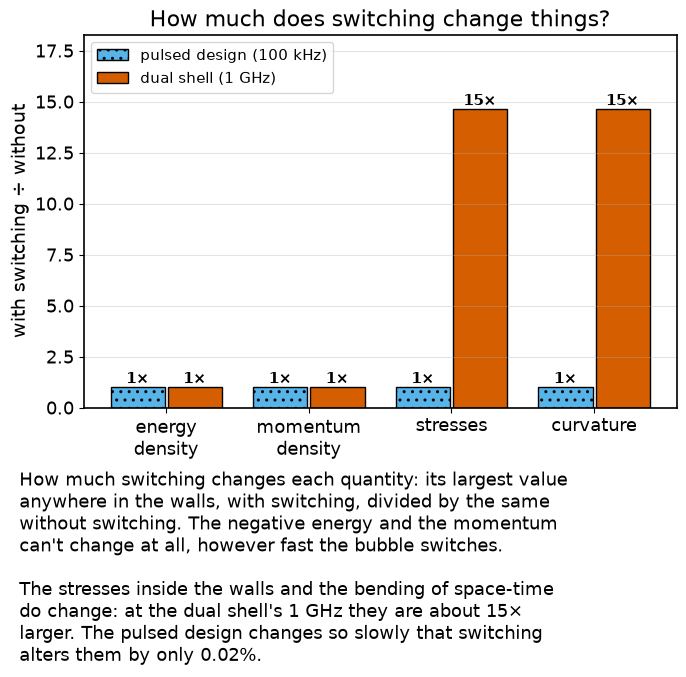

saved 06_switching_effects.png


In [23]:
fig, ax = phone_figure(1, height_per_row=4.6)
labels = ["energy\ndensity", "momentum\ndensity", "stresses", "curvature"]
dual_vals = [1.0, 1.0, STRESS_RATIO, CURV_RATIO]
pulsed_vals = [1.0, 1.0, tdep.max_stress(SHELLS_PULSED, 1 / F_PULSE, True) / tdep.max_stress(SHELLS_PULSED, 1 / F_PULSE, False),
               1.0 + PULSED_EFFECT]
xb = np.arange(4)
b1 = ax.bar(xb - 0.2, pulsed_vals, 0.38, color=COLORS["sky"], edgecolor="black", hatch="..", label="pulsed design (100 kHz)")
b2 = ax.bar(xb + 0.2, dual_vals, 0.38, color=COLORS["vermillion"], edgecolor="black", label="dual shell (1 GHz)")
for bars in (b1, b2):
    for bar in bars:
        v = bar.get_height()
        ax.annotate(f"{v:.0f}×" if v > 1.5 else "1×", (bar.get_x() + bar.get_width() / 2, v), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=11, fontweight="bold")
ax.set_xticks(xb, labels)
ax.set_ylim(0, max(dual_vals) * 1.25)
ax.set_ylabel("with switching ÷ without")
ax.set_title("How much does switching change things?")
ax.legend(loc="upper left", fontsize=11)
ax.grid(axis="x", visible=False)

path = save_figure(fig, "06_switching_effects", f'''
How much switching changes each quantity: its largest value anywhere in the walls, with switching, divided by the same without switching. The negative energy and the momentum can't change at all, however fast the bubble switches.

The stresses inside the walls and the bending of space-time do change: at the dual shell's 1 GHz they are about {CURV_RATIO:.0f}× larger. The pulsed design changes so slowly that switching alters them by only {PULSED_EFFECT * 100:.2f}%.
''')
plt.show()
print("saved", path.name)

### The quantum rule again, now with switching

Section 3's test only trusts the quantum rule over time windows shorter than the time light takes to cross the bending length of space-time. Faster switching bends space-time more sharply, so the window shrinks, and over a shorter window the rule allows stronger negative energy. So switching *loosens* the test. The question is by how much. We use exactly Section 3's choices, including the most generous curvature anywhere in the walls at any moment of the cycle. One extra step: when the window is longer than a cycle, the energy at the worst spot rises and falls during the window, and we average it the way the rule prescribes.

We also run a stricter version that only counts the bending of space-time at the bubble's equator, where the strongest negative energy actually sits. Switching bends space-time there too, about half as much as at its worst point, so the stricter version is about 4× tougher but tells the same story.

In [24]:
from scipy.constants import G as G_NEWTON, hbar

freqs = np.logspace(5, 42, 38)
sweep = [tdep.dual_shell_qi({**AS_WRITTEN, "omega": 2 * np.pi * f}, BETA, ALPHA, True, n_phase=32) for f in freqs]
V_sweep = np.array([s.violation for s in sweep])
QI_FROZEN = tdep.dual_shell_qi(AS_WRITTEN, BETA, ALPHA, False)
QI_1GHZ = tdep.dual_shell_qi(AS_WRITTEN, BETA, ALPHA, True)
F_PASS = 10 ** np.interp(0.0, np.log10(V_sweep)[::-1], np.log10(freqs)[::-1])
T_PLANCK = np.sqrt(hbar * G_NEWTON / C_LIGHT**5)
L_PLANCK = quantum.PLANCK_LENGTH
F_CROSS = CURV_FROZEN * C_LIGHT / (2 * np.pi * BETA * AS_WRITTEN["sigma"] / 2)   # where β(ω/c)(σ/2) = frozen curvature

print(f"without switching:  over the limit by {QI_FROZEN.violation:.1e}")
print(f"at 1 GHz:           over the limit by {QI_1GHZ.violation:.1e}  ({QI_FROZEN.violation / QI_1GHZ.violation:.0f}× looser)")
print(f"would pass only above f ≈ {F_PASS:.1e} Hz: one cycle = {1 / F_PASS:.1e} s = {1 / F_PASS / T_PLANCK:.0f} Planck times;")
print(f"  light travels {C_LIGHT / F_PASS / L_PLANCK:.0f} Planck lengths per cycle")
print(f"\nswitching starts to dominate the curvature above about {F_CROSS / 1e6:.0f} MHz "
      f"(the notes estimated ~300 MHz from the wall's light-crossing time)")

# Closed form for the passing frequency (derived independently by AGY3): far above the crossover the
# Lorentzian average is ½ρ_peak and r_min² = 1/(β(ω/c)(σ/2)), so β and σ cancel: f = α²/(2√(6π) t_P).
F_CLOSED = ALPHA**2 / (2 * np.sqrt(6 * np.pi) * T_PLANCK)
print(f"closed form: f = α²/(2√(6π)·t_P) = {F_CLOSED:.3e} Hz  (numerical sweep: {F_PASS:.3e} Hz); "
      "independent of the bubble's speed and wall sharpness")

# Stricter version: only count curvature at the equator, where the strongest negative energy sits.
QI_EQ = tdep.dual_shell_qi(AS_WRITTEN, BETA, ALPHA, True, equator_only=True)
V_EQ_HIGH = tdep.dual_shell_qi({**AS_WRITTEN, "omega": 2 * np.pi * 1e30}, BETA, ALPHA, True, equator_only=True).violation
F_PASS_EQ = 1e30 * np.sqrt(V_EQ_HIGH)          # violation ∝ f⁻² in this regime (tested)
print(f"\nstricter (equator-only curvature): 1 GHz over by {QI_EQ.violation:.1e}; passes above ≈ {F_PASS_EQ:.1e} Hz")

without switching:  over the limit by 2.0e+65
at 1 GHz:           over the limit by 6.4e+62  (306× looser)
would pass only above f ≈ 2.1e+40 Hz: one cycle = 4.7e-41 s = 868 Planck times;
  light travels 868 Planck lengths per cycle

switching starts to dominate the curvature above about 68 MHz (the notes estimated ~300 MHz from the wall's light-crossing time)
closed form: f = α²/(2√(6π)·t_P) = 2.136e+40 Hz  (numerical sweep: 2.136e+40 Hz); independent of the bubble's speed and wall sharpness

stricter (equator-only curvature): 1 GHz over by 2.3e+63; passes above ≈ 4.3e+40 Hz


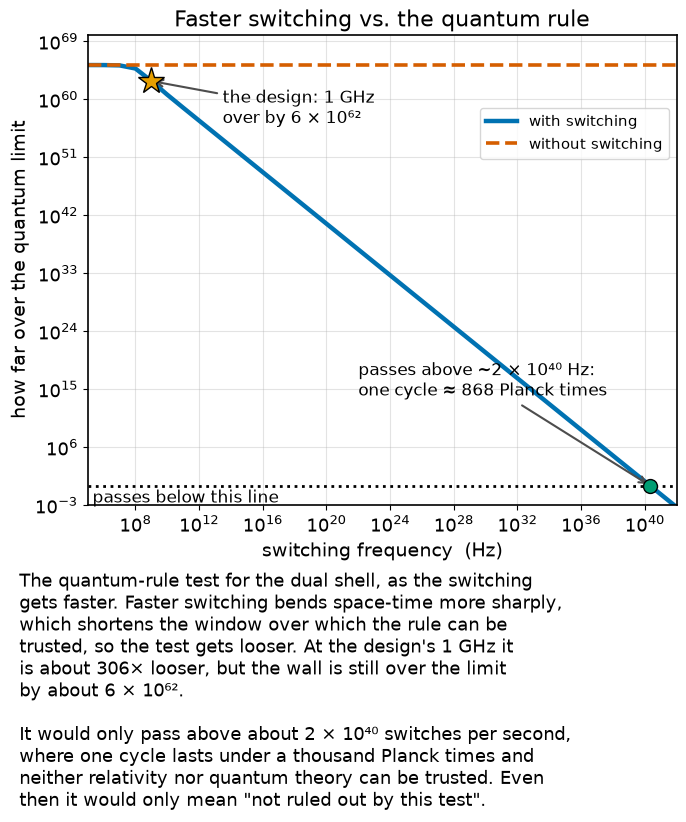

saved 06b_switching_quantum_rule.png


In [25]:
fig, ax = phone_figure(1, height_per_row=5.6)
ax.loglog(freqs, V_sweep, color=COLORS["blue"], lw=3.2, label="with switching")
ax.axhline(QI_FROZEN.violation, color=COLORS["vermillion"], ls="--", lw=2.6, label="without switching")
ax.axhline(1.0, color="black", ls=":", lw=2.0)
ax.text(2e5, 0.25, "passes below this line", fontsize=12, va="top")
ax.plot(1e9, QI_1GHZ.violation, marker="*", ms=20, color=COLORS["orange"], mec="black", zorder=5)
ax.annotate(f"the design: 1 GHz\nover by {sci_text(QI_1GHZ.violation, 0)}", (1e9, QI_1GHZ.violation),
            xytext=(3e13, 2e56), fontsize=12, arrowprops=dict(arrowstyle="->", color="0.3", lw=1.5))
ax.plot(F_PASS, 1.0, marker="o", ms=10, color=COLORS["green"], mec="black", zorder=5)
ax.annotate(f"passes above ~{sci_text(F_PASS, 0)} Hz:\none cycle ≈ {1 / F_PASS / T_PLANCK:.0f} Planck times",
            (F_PASS, 1.0), xytext=(1e22, 1e14), fontsize=12, arrowprops=dict(arrowstyle="->", color="0.3", lw=1.5))
ax.set_xlim(1e5, 1e42)
ax.set_ylim(1e-3, 1e70)
ax.set_xlabel("switching frequency  (Hz)")
ax.set_ylabel("how far over the quantum limit")
ax.set_title("Faster switching vs. the quantum rule")
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.86), fontsize=11)

path = save_figure(fig, "06b_switching_quantum_rule", f'''
The quantum-rule test for the dual shell, as the switching gets faster. Faster switching bends space-time more sharply, which shortens the window over which the rule can be trusted, so the test gets looser. At the design's 1 GHz it is about {QI_FROZEN.violation / QI_1GHZ.violation:.0f}× looser, but the wall is still over the limit by about {sci_text(QI_1GHZ.violation, 0)}.

It would only pass above about {sci_text(F_PASS, 0)} switches per second, where one cycle lasts under a thousand Planck times and neither relativity nor quantum theory can be trusted. Even then it would only mean "not ruled out by this test".
''')
plt.show()
print("saved", path.name)

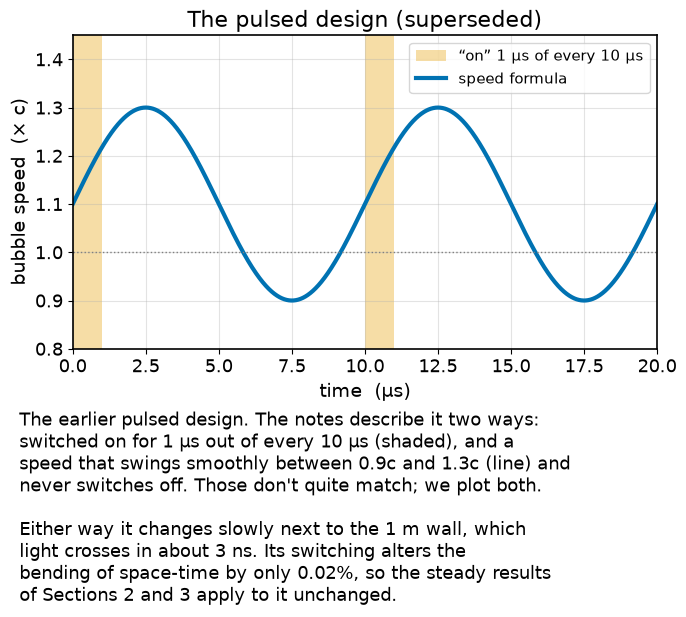

saved 06c_pulsed_design.png


In [26]:
t_p = np.linspace(0, 2 / F_PULSE, 2001)
fig, ax = phone_figure(1, height_per_row=4.0)
for k in range(2):
    ax.axvspan(k * 10, k * 10 + 1, color=COLORS["orange"], alpha=0.35, lw=0, label="“on” 1 µs of every 10 µs" if k == 0 else None)
ax.plot(t_p * 1e6, 1.1 + 0.2 * np.sin(2 * np.pi * F_PULSE * t_p), color=COLORS["blue"], lw=3, label="speed formula")
ax.axhline(1.0, color="0.5", lw=1, ls=":")
ax.set_xlabel("time  (µs)")
ax.set_ylabel("bubble speed  (× c)")
ax.set_ylim(0.8, 1.45)
ax.set_xlim(0, 20)
ax.set_title("The pulsed design (superseded)")
ax.legend(loc="upper right", fontsize=11)

path = save_figure(fig, "06c_pulsed_design", f'''
The earlier pulsed design. The notes describe it two ways: switched on for 1 µs out of every 10 µs (shaded), and a speed that swings smoothly between 0.9c and 1.3c (line) and never switches off. Those don't quite match; we plot both.

Either way it changes slowly next to the 1 m wall, which light crosses in about 3 ns. Its switching alters the bending of space-time by only {PULSED_EFFECT * 100:.2f}%, so the steady results of Sections 2 and 3 apply to it unchanged.
''')
plt.show()
print("saved", path.name)

**What holds up.**
- Switching really does change the geometry, and the author's instinct about *when* it matters is close. The notes compare the switching rate with the time light takes to cross the wall, which gives about 300 MHz. The full calculation says switching starts to dominate the curvature at about 70 MHz (printed above). Most of the gap is a factor of 2π between "cycles per second" and the angular frequency the equations use; with it included, the notes' estimate becomes about 48 MHz, within 1.5× of the full answer.
- Faster switching genuinely loosens the quantum-inequality test. That's a real effect, not a mistake.

**What the numbers say.**
- Switching can't change the amount of negative energy, at any speed.
- At 1 GHz it makes the stresses and the bending of space-time about 15× larger, and loosens the quantum test about 300×. The design is still over the limit by about 10⁶² (about 10⁶³ in the stricter version).
- The switching rate needed to pass, about 2 × 10⁴⁰ per second, doesn't depend on the bubble's speed or how sharp its walls are. It comes out of the quantum rule and gravity alone.
- To pass, the switching would have to be about 10³¹ times faster than designed, into a regime where today's physics doesn't apply.

**Read the loosening carefully.** A shorter trusted window means the test can rule out less; it doesn't mean nature allows more. Whether such extreme negative energies are possible in strongly time-dependent, strongly curved space-time is an open research question, and this test can't settle it.

**Not covered here.** We report the largest stresses, not a detailed map of them. The quantum test neglects the bubble's centimetre-scale rocking. And the rule itself is the one for the simplest quantum field (Section 3's caveats all still apply).

## 7. The summary to send

`summary.pdf` (in the repo's top folder) is the short version to send or print: five pages, one chart per page, each with a one-line bottom line. Every number in it comes from the calculations above, so rerunning the notebook rebuilds it.

In [27]:
from warp.summary import build_summary

summary_numbers = dict(
    best_saving=M_1M / M_BEST,          # Section 2: best cosine wall vs a 1 m wall
    best_delta=D_BEST,                  # Section 2: sweet-spot thickness (m)
    qi_1m=qi[1.0].violation,            # Section 3: 1 m wall, how far over the quantum limit
    swing_cm=swing_cm,                  # Section 4: largest rocking of the ship (cm)
    qi_1ghz=QI_1GHZ.violation,          # Section 6: dual shell at 1 GHz
    f_pass=F_PASS,                      # Section 6: switching rate needed to pass (Hz)
    f_cross_mhz=F_CROSS / 1e6,          # Section 6: where switching starts to dominate (MHz)
)
pdf_path = build_summary(summary_numbers)
print(f"saved {pdf_path.name} ({pdf_path.stat().st_size / 1e6:.1f} MB)")
for k, v in summary_numbers.items():
    print(f"  {k:<12} {v:.4g}")

saved summary.pdf (0.9 MB)
  best_saving  48.95
  best_delta   188.1
  qi_1m        4.051e+64
  swing_cm     19.09
  qi_1ghz      6.39e+62
  f_pass       2.136e+40
  f_cross_mhz  68.36
